# 01 — Exploring the IXI cohort

Goal of this notebook: get your hands on the dataset. By the end you will have (1) loaded the subject roster you built, (2) looked at the age distribution of your cohort, and (3) viewed one brain scan in three planes.

Every code cell starts with comments: the task, hints, and what the output should roughly look like. **The code itself is yours to write.** If you get stuck, paste the error to Astro.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from pathlib import Path

In [ ]:
subs = pd.read_csv("subjects.csv")
print(subs.head())
print(subs.shape)
print(subs['age'].notna().sum())


  subject        age                        file
0  IXI002  35.800137  IXI002-Guys-0828-T1.nii.gz
1  IXI012  38.781656    IXI012-HH-1211-T1.nii.gz
2  IXI013  46.710472    IXI013-HH-1212-T1.nii.gz
3  IXI014  34.236824    IXI014-HH-1236-T1.nii.gz
4  IXI015  24.284736    IXI015-HH-1258-T1.nii.gz
(581, 3)
563


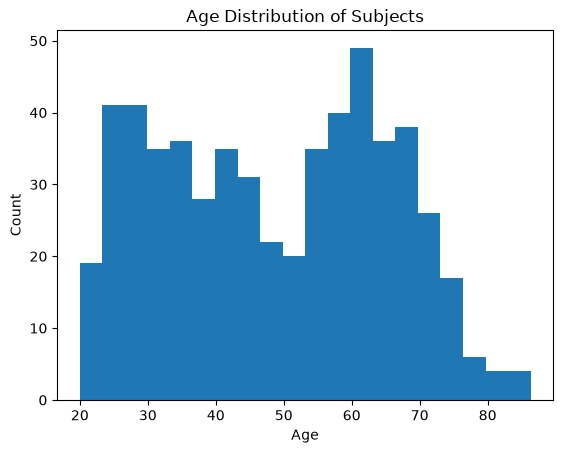

In [ ]:
ages = subs['age'].dropna()
plt.hist(ages, bins=20)
plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age Distribution of Subjects')
plt.show()

In [9]:
row = subs[subs['subject'] == 'IXI002'].iloc[0]
path = Path('data/IXI-T1') / row['file']
img = nib.load(path)
print("Image shape:", img.shape)
print("Voxel zooms:", img.header.get_zooms())



Image shape: (256, 256, 150)
Voxel zooms: (np.float32(0.9375), np.float32(0.9375), np.float32(1.199997))


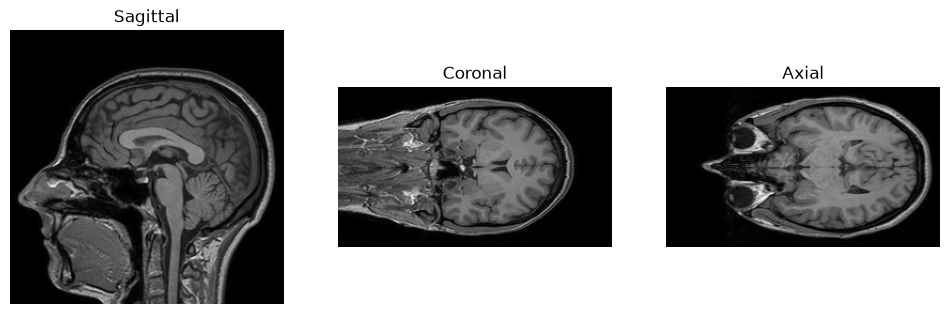

('P', 'S', 'R')


In [12]:

data = img.get_fdata()
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
# Sagittal
axes[0].imshow(np.rot90(data[ :, :, 75]), cmap='gray')
axes[0].axis('off')
axes[0].set_title('Sagittal')
# Coronal
axes[1].imshow(np.rot90(data[128 ,:, :]), cmap='gray')
axes[1].axis('off')
axes[1].set_title('Coronal')
# Axial
axes[2].imshow(np.rot90(data[:, 128, :]), cmap='gray')
axes[2].axis('off')
axes[2].set_title('Axial')
plt.show()

print(nib.aff2axcodes(img.affine))


## Checkpoint notes

### How old is your cohort, roughly? Is the age spread even? One thing you noticed looking at the slices.

The cohort is roughly 20-85. Around 70-85 the number of subjects begins to fall towards 0. 